# Airline Value & Customer Experience Analysis

Exploratory analysis of July 2026 BTS flight records. Work in progress. See the repository README for data setup, metric definitions, and limitations.

## 1. Dataset overview

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/raw/T_ONTIME_REPORTING.csv")
df.head()


,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN,DEST_AIRPORT_ID,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,...,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
0,7/1/2026 12:00:00 AM,AA,1,12478,JFK,12892,LAX,705,704.0,-1.0,...,0.0,377.0,347.0,311.0,2475.0,NaN,NaN,NaN,NaN,NaN
1,7/1/2026 12:00:00 AM,AA,10,12892,LAX,12478,JFK,2130,2137.0,7.0,...,0.0,330.0,323.0,295.0,2475.0,NaN,NaN,NaN,NaN,NaN
2,7/1/2026 12:00:00 AM,AA,1002,13485,MSN,11057,CLT,700,651.0,-9.0,...,0.0,136.0,122.0,95.0,708.0,NaN,NaN,NaN,NaN,NaN
3,7/1/2026 12:00:00 AM,AA,1004,13930,ORD,15016,STL,2300,2255.0,-5.0,...,0.0,76.0,73.0,43.0,258.0,NaN,NaN,NaN,NaN,NaN
4,7/1/2026 12:00:00 AM,AA,1007,11057,CLT,14193,PNS,2028,2022.0,-6.0,...,0.0,99.0,93.0,67.0,488.0,NaN,NaN,NaN,NaN,NaN


In [3]:
df.shape

(631970, 25)

In [4]:
df.columns

Index(['FL_DATE', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_FL_NUM',
       'ORIGIN_AIRPORT_ID', 'ORIGIN', 'DEST_AIRPORT_ID', 'DEST',
       'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'CRS_ARR_TIME', 'ARR_TIME',
       'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED',
       'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE',
       'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY',
       'LATE_AIRCRAFT_DELAY'],
      dtype='str')

## 2. Data quality and missing values

In [5]:
df.info()
df.isna().sum().sort_values(ascending=False)
(df.isna().sum() / len(df) * 100).sort_values(ascending=False)

<class 'pandas.DataFrame'>
RangeIndex: 631970 entries, 0 to 631969
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   FL_DATE              631970 non-null  str    
 1   OP_UNIQUE_CARRIER    631970 non-null  str    
 2   OP_CARRIER_FL_NUM    631970 non-null  int64  
 3   ORIGIN_AIRPORT_ID    631970 non-null  int64  
 4   ORIGIN               631970 non-null  str    
 5   DEST_AIRPORT_ID      631970 non-null  int64  
 6   DEST                 631970 non-null  str    
 7   CRS_DEP_TIME         631970 non-null  int64  
 8   DEP_TIME             616585 non-null  float64
 9   DEP_DELAY            616505 non-null  float64
 10  CRS_ARR_TIME         631970 non-null  int64  
 11  ARR_TIME             614860 non-null  float64
 12  ARR_DELAY            612038 non-null  float64
 13  CANCELLED            631970 non-null  float64
 14  CANCELLATION_CODE    16530 non-null   str    
 15  DIVERTED             631970 

CANCELLATION_CODE      97.384370
LATE_AIRCRAFT_DELAY    72.552495
SECURITY_DELAY         72.552495
CARRIER_DELAY          72.552495
WEATHER_DELAY          72.552495
NAS_DELAY              72.552495
ACTUAL_ELAPSED_TIME     3.153947
ARR_DELAY               3.153947
AIR_TIME                3.153947
ARR_TIME                2.707407
DEP_DELAY               2.447110
DEP_TIME                2.434451
ORIGIN                  0.000000
OP_CARRIER_FL_NUM       0.000000
ORIGIN_AIRPORT_ID       0.000000
OP_UNIQUE_CARRIER       0.000000
FL_DATE                 0.000000
CRS_DEP_TIME            0.000000
DEST                    0.000000
DEST_AIRPORT_ID         0.000000
CRS_ARR_TIME            0.000000
CRS_ELAPSED_TIME        0.000000
DIVERTED                0.000000
CANCELLED               0.000000
DISTANCE                0.000000
dtype: float64

In [6]:
df["CANCELLED"].value_counts()
df["CANCELLED"].value_counts(normalize=True) * 100

CANCELLED
0.0    97.38437
1.0     2.61563
Name: proportion, dtype: float64

In [7]:
df["DIVERTED"].value_counts()
df["DIVERTED"].value_counts(normalize=True) * 100

DIVERTED
0.0    99.461683
1.0     0.538317
Name: proportion, dtype: float64

In [8]:
missing_airtime = df[df["AIR_TIME"].isna()]
missing_airtime[["CANCELLED", "DIVERTED"]].value_counts()

CANCELLED  DIVERTED
1.0        0.0         16530
0.0        1.0          3402
Name: count, dtype: int64

## 3. Airline reliability

Completed flights exclude cancellations and diversions. Arrival delays are at least 15 minutes; cancellation rates use all scheduled flights.

In [9]:
completed = df[(df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)].copy()

print(completed.shape)
completed["ARR_DELAY"].describe()

(612038, 25)


count    612038.000000
mean         15.603054
std          71.846150
min         -86.000000
25%         -14.000000
50%          -3.000000
75%          19.000000
max        3425.000000
Name: ARR_DELAY, dtype: float64

In [10]:
(completed["ARR_DELAY"] >= 15).mean() * 100

np.float64(28.34154088471631)

In [11]:
completed["LATE_15"] = completed["ARR_DELAY"] >= 15

delay_by_airline = completed.groupby("OP_UNIQUE_CARRIER")["LATE_15"].mean() * 100

delay_by_airline.sort_values()

OP_UNIQUE_CARRIER
MQ    18.780321
AS    23.197522
OO    23.900154
YX    24.506380
DL    25.903087
UA    26.574276
G4    30.772148
WN    30.816187
AA    33.077793
F9    35.051233
OH    36.479247
B6    37.774160
Name: LATE_15, dtype: float64

In [12]:
completed["OP_UNIQUE_CARRIER"].value_counts()

airline_summary = pd.DataFrame({
    "Total_Flights": completed["OP_UNIQUE_CARRIER"].value_counts(),
    "Delay_Rate": delay_by_airline
})

airline_summary.sort_values("Delay_Rate").round(2)

,Total_Flights,Delay_Rate
OP_UNIQUE_CARRIER,,
MQ,29270,18.78
AS,31318,23.20
OO,75556,23.90
YX,28919,24.51
DL,91298,25.90
UA,72446,26.57
G4,13184,30.77
WN,122864,30.82
AA,86614,33.08


In [13]:
cancellation_by_airline = df.groupby("OP_UNIQUE_CARRIER")["CANCELLED"].mean() * 100

cancellation_by_airline.sort_values()

OP_UNIQUE_CARRIER
G4    0.548295
AS    0.811186
WN    1.135254
MQ    1.480860
OO    1.547903
UA    1.954594
AA    2.293722
DL    2.401742
F9    3.398106
OH    6.599292
YX    9.329219
B6    9.776081
Name: CANCELLED, dtype: float64

In [14]:
airline_summary["Cancellation_Rate"] = cancellation_by_airline

airline_summary.sort_values("Cancellation_Rate").round(2)

,Total_Flights,Delay_Rate,Cancellation_Rate
OP_UNIQUE_CARRIER,,,
G4,13184,30.77,0.55
AS,31318,23.20,0.81
WN,122864,30.82,1.14
MQ,29270,18.78,1.48
OO,75556,23.90,1.55
UA,72446,26.57,1.95
AA,86614,33.08,2.29
DL,91298,25.90,2.40
F9,19714,35.05,3.40


## 4. Flights departing Orlando (MCO)

In [15]:
mco_flights = df[df["ORIGIN"] == "MCO"]

mco_flights.shape

(13136, 25)

In [16]:
mco_flights["DEST"].value_counts().head(10)

DEST
ATL    693
SJU    645
DFW    439
ORD    438
PHL    426
CLT    403
DEN    398
BWI    398
JFK    390
DCA    387
Name: count, dtype: int64

## 5. MCO → JFK airline comparison

In [17]:
mco_jfk = mco_flights[mco_flights["DEST"] == "JFK"]

mco_jfk["OP_UNIQUE_CARRIER"].value_counts()

OP_UNIQUE_CARRIER
B6    235
DL    155
Name: count, dtype: int64

In [18]:
mco_jfk_completed = completed[
    (completed["ORIGIN"] == "MCO") &
    (completed["DEST"] == "JFK")
]

print(mco_jfk_completed.shape)

mco_jfk_completed.groupby("OP_UNIQUE_CARRIER")["LATE_15"].mean() * 100

(346, 26)


OP_UNIQUE_CARRIER
B6    40.00000
DL    36.30137
Name: LATE_15, dtype: float64

In [19]:
mco_jfk_completed["OP_UNIQUE_CARRIER"].value_counts()

OP_UNIQUE_CARRIER
B6    200
DL    146
Name: count, dtype: int64

In [20]:
cancelled_mco_jfk = mco_jfk.groupby("OP_UNIQUE_CARRIER")["CANCELLED"].mean() * 100

cancelled_mco_jfk.sort_values()

OP_UNIQUE_CARRIER
DL     5.806452
B6    14.468085
Name: CANCELLED, dtype: float64

In [21]:
mco_jfk.groupby("OP_UNIQUE_CARRIER")["DIVERTED"].sum()

OP_UNIQUE_CARRIER
B6    1.0
DL    0.0
Name: DIVERTED, dtype: float64

## 6. Initial departure-time exploration

In [22]:
print(mco_jfk_completed["CRS_DEP_TIME"].head(10))

mco_jfk_completed["CRS_DEP_TIME"].describe()

3837    1403
3874     705
3912    1829
4044    1104
4192     600
4247    1608
4283     943
4480    2002
5267    1959
5465    1105
Name: CRS_DEP_TIME, dtype: int64


count     346.000000
mean     1220.716763
std       503.247697
min       600.000000
25%       736.250000
50%      1115.000000
75%      1609.750000
max      2005.000000
Name: CRS_DEP_TIME, dtype: float64

## Day 2 — EDA Progress Summary (October 10, 2026)

### Project: Airline Value & Customer Experience Analysis

**Main project goal:** Analyze airline prices, reliability, and customer satisfaction to eventually develop a tool that helps consumers find the best-value flights while also exploring airline marketing and customer loyalty.

### What I accomplished today

**1. Updated and explored the dataset**
- Downloaded the updated July 2026 BTS flight dataset, including `ARR_DELAY`.
- Dataset contains 631,970 flights.
- Created a `completed` DataFrame containing 612,038 flights, excluding cancellations and diversions.
- Examined arrival-delay statistics using `.describe()`.

**2. Analyzed airline reliability**
- Found that 28.34% of completed flights arrived at least 15 minutes late.
- Calculated arrival-delay rates for individual airlines.
- Calculated cancellation rates using the original dataset.
- Created an `airline_summary` DataFrame containing flight counts, arrival-delay rates, and cancellation rates.

**3. Investigated flights departing Orlando**
- Filtered flights departing Orlando International Airport (`MCO`).
- Used `.value_counts()` to identify the 10 most common destinations.
- Selected MCO → JFK for a more detailed comparison of airlines.

**4. Compared JetBlue and Delta on MCO → JFK**

| Metric | JetBlue | Delta |
|---|---:|---:|
| Scheduled flights | 235 | 155 |
| Completed flights | 200 | 146 |
| Arrival-delay rate | 40.00% | 36.30% |
| Cancellation rate | 14.47% | 5.81% |
| Diverted flights | 1 | 0 |

**Findings:** Delta had a slightly lower arrival-delay rate and a considerably lower cancellation rate on this route during July 2026. However, these results represent only one month and do not necessarily indicate long-term reliability.

**5. Began investigating departure times**
- Examined the `CRS_DEP_TIME` column.
- Found 346 completed flights between MCO and JFK.
- Earliest scheduled departure: 6:00 AM.
- Latest scheduled departure: 8:05 PM.
- Learned that scheduled times are stored in HHMM format and should not be treated as ordinary numerical values when calculating averages.

### Pandas concepts practiced

- Boolean filtering with `df[...]`
- Combining conditions with `&`
- Creating new columns
- `.groupby()`
- `.mean()` and `.sum()`
- `.value_counts()`
- `.sort_values()`
- `.head()` and `.describe()`
- Creating summary DataFrames
- Understanding sample sizes and the difference between scheduled and completed flights

**Important:** Continue EDA carefully rather than rushing into regression. We still want to explore routes, airports, timing, missing data, and flight reliability before developing predictive models.

### Current project status

- Data collection: Initial dataset obtained
- Data cleaning and EDA: In progress
- Visualizations: Not started
- Ticket-price analysis: Not started
- Customer satisfaction / marketing analysis: Not started
- SQL / Excel analysis: Not started
- Regression / predictive modeling: Not started
- Flight comparison tool: Not started

**Next starting point:** Return to `mco_jfk_completed` and learn how to extract the departure hour from `CRS_DEP_TIME` using Python.

### Day 3:

In [23]:
df["departure_hour"] = df["CRS_DEP_TIME"] // 100

mco_jfk_completed["departure_hour"] = mco_jfk_completed["CRS_DEP_TIME"] // 100

df[["CRS_DEP_TIME", "departure_hour"]].head(10)

,CRS_DEP_TIME,departure_hour
0,705,7
1,2130,21
2,700,7
3,2300,23
4,2028,20
5,616,6
6,2245,22
7,1946,19
8,2133,21
9,1740,17


In [24]:
mco_jfk_completed["departure_hour"].value_counts().sort_index()

mco_jfk_completed["time_of_day"] = pd.cut(
    mco_jfk_completed["departure_hour"],
    bins = [-1, 5, 11, 17, 23],
    labels= ["Overnight", "Morning", "Afternoon", "Evening"]
                                    
)

mco_jfk_completed["time_of_day"].value_counts()

time_of_day
Morning      196
Evening       79
Afternoon     71
Overnight      0
Name: count, dtype: int64

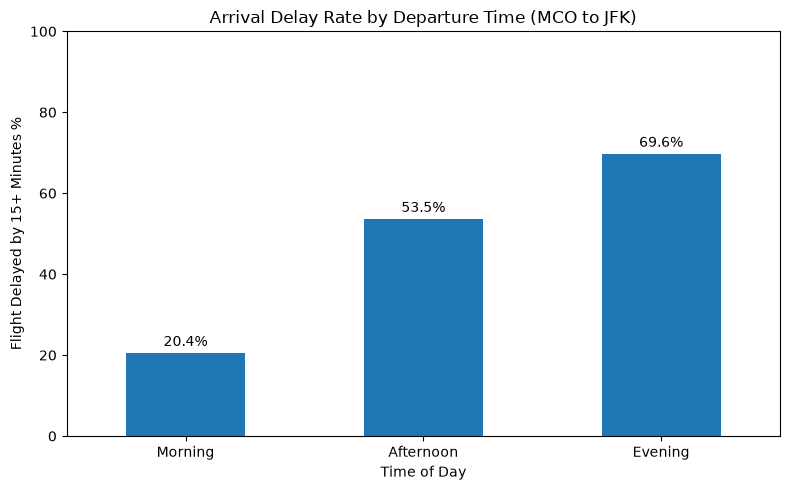

In [25]:
delay_by_time = mco_jfk_completed.groupby("time_of_day", observed=True)["LATE_15"].mean() * 100

import matplotlib.pyplot as plt

ax = delay_by_time.plot(kind="bar", figsize=(8, 5))

ax.set_title("Arrival Delay Rate by Departure Time (MCO to JFK)")
ax.set_xlabel("Time of Day")
ax.set_ylabel("Flight Delayed by 15+ Minutes %")

ax.tick_params(axis="x", rotation=0)
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

In [26]:
mco_jfk_completed.groupby(
    ["OP_UNIQUE_CARRIER", "time_of_day"], observed= True
)["LATE_15"].mean() * 100

OP_UNIQUE_CARRIER  time_of_day
B6                 Morning        18.691589
                   Afternoon      53.488372
                   Evening        74.000000
DL                 Morning        22.471910
                   Afternoon      53.571429
                   Evening        62.068966
Name: LATE_15, dtype: float64

In [27]:
mco_jfk_completed.groupby(
    ["OP_UNIQUE_CARRIER", "time_of_day"], observed= True
)["LATE_15"].size()

OP_UNIQUE_CARRIER  time_of_day
B6                 Morning        107
                   Afternoon       43
                   Evening         50
DL                 Morning         89
                   Afternoon       28
                   Evening         29
Name: LATE_15, dtype: int64

In [28]:
pd.crosstab(
    index= mco_jfk_completed["OP_UNIQUE_CARRIER"],
    columns= mco_jfk_completed["time_of_day"],
    normalize="index"
) * 100

time_of_day,Morning,Afternoon,Evening
OP_UNIQUE_CARRIER,,,
B6,53.500000,21.500000,25.000000
DL,60.958904,19.178082,19.863014


### Day 3 — EDA Summary (October 23, 2026)

**Focus:** Investigating how departure time affects flight reliability on the MCO → JFK route.

**What I accomplished:**
- Extracted departure hours using floor division (`// 100`).
- Created time-of-day categories using `pd.cut()`.
- Analyzed arrival-delay rates by departure time and airline using `groupby()`.
- Created my first Matplotlib bar chart.
- Used `.size()` and `pd.crosstab()` to compare flight counts and departure-time distributions.

**Key Findings:**
- Morning flights had the lowest arrival-delay rate (20.41%), followed by afternoon (53.52%) and evening (69.62%).
- Delta operated a larger proportion of its completed flights in the morning (60.96%) than JetBlue (53.50%).
- JetBlue operated more of its completed flights in the evening (25.00%) than Delta (19.86%).
- Departure-time differences may partly explain the airlines' overall reliability differences, but further investigation is needed.

**Next Session — Day 4:**
- Investigate whether departure schedules explain the difference in airline delay rates using standardization.
- Expand departure-time analysis to other routes and airports.
- Continue exploring patterns and developing visualizations.

*Note: Findings are based on completed MCO → JFK flights during July 2026 and should not be generalized without additional data.*

### Day 4:

In [39]:
mjfk_weights = mco_jfk_completed["time_of_day"].value_counts(
    normalize=True
)

mcojfk_time_rates = mco_jfk_completed.groupby(
    ["OP_UNIQUE_CARRIER", "time_of_day"], observed= True
)["LATE_15"].mean().unstack()

In [45]:
mjfk_weights = mjfk_weights[mjfk_weights > 0]

mcojfk_time_rates.mul(mjfk_weights, axis=1).sum(axis= 1) * 100

OP_UNIQUE_CARRIER
B6    38.460190
DL    37.894549
dtype: float64